# 05 — Modèle de demande : prédire le volume à un prix donné

L'élasticité du notebook 04 est **une constante**. C'est puissant pour
raisonner, mais réducteur : elle suppose que la réaction au prix est la même
pour tous les produits, à toutes les saisons, à tous les niveaux de prix.

Un modèle ML relâche cette hypothèse. En contrepartie, il pose un problème
nouveau et sérieux :

> **Un modèle de demande peut avoir un excellent RMSE et être totalement
> inutilisable pour fixer un prix.**

Il lui suffit de tout expliquer par la saisonnalité, l'ancienneté et la demande
passée, et de traiter le prix comme du bruit. Sa courbe de demande est alors
plate — et l'optimiseur recommandera systématiquement le prix maximum autorisé.

Ce notebook construit le modèle **et** les métriques qui détectent ce piège.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
from optimization_pricing.dataset import load_panel
from optimization_pricing.modeling.train import temporal_split

panel = load_panel("product", processed=True)
train, test = temporal_split(panel)

C:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-08-20 10:42:27.710 | INFO     | optimization_pricing.modeling.train:temporal_split:65 - Split temporel a 2018-05-01 : train=22,154 (2017-01-01 -> 2018-04-01), test=6,482 (2018-05-01 -> 2018-08-01)


## 1. Pourquoi un split temporel, jamais aléatoire

Un split aléatoire laisserait le modèle voir *mai 2018* d'un produit pour
prédire *mars 2018* du même produit. Comme les features contiennent des retards
et des moyennes glissantes, l'information circule et les scores deviennent
fictifs.

On coupe donc sur le temps : entraînement sur le passé, test sur le futur.

In [3]:
resume = pd.DataFrame(
    {
        "periode": [f"{train['month'].min():%Y-%m} -> {train['month'].max():%Y-%m}",
                    f"{test['month'].min():%Y-%m} -> {test['month'].max():%Y-%m}"],
        "observations": [len(train), len(test)],
        "produits": [train["product_id"].nunique(), test["product_id"].nunique()],
        "quantite moyenne": [train["quantity"].mean(), test["quantity"].mean()],
    },
    index=["train", "test"],
)
resume

,periode,observations,produits,quantite moyenne
train,2017-01 -> 2018-04,22154,5687,2.377
test,2018-05 -> 2018-08,6482,3300,2.434


## 2. Deux corrections indispensables

### (a) La correction de retransformation (smearing de Duan)

Le modèle prédit `log(Q)`, mais l'optimiseur a besoin de `Q`. Or
`exp(E[log Q]) ≠ E[Q]` — inégalité de Jensen. Reprendre naïvement l'exponentielle
sous-estime systématiquement la demande.

Le facteur de Duan corrige cela sans hypothèse de normalité :
`smearing = moyenne(exp(résidus))` sur le train.

### (b) La contrainte de monotonie

On **impose** au modèle que la demande ne puisse pas augmenter avec le prix.
Ce n'est pas une contrainte technique, c'est une contrainte **économique** : sans
elle, le bruit produit des courbes de demande localement croissantes, et
l'argmax de profit se cale sur un artefact numérique.

In [4]:
from optimization_pricing.config import MONOTONE_CONSTRAINTS, NUMERIC_FEATURES, PRICE_FEATURES

pd.DataFrame(
    {"feature": NUMERIC_FEATURES, "contrainte monotone": MONOTONE_CONSTRAINTS}
).assign(**{"variable de prix": lambda d: d["feature"].isin(PRICE_FEATURES)})

,feature,contrainte monotone,variable de prix
0,log_price,-1,True
1,price_rel_product,-1,True
2,price_rel_category,-1,True
3,log_freight,0,False
4,log_weight,0,False
5,product_photos_qty,0,False
6,log_description_length,0,False
7,review_score_hist,0,False
8,n_sellers_lag1,0,False
9,share_installments_lag1,0,False


Les trois variables de prix portent une contrainte `-1` (décroissante) ; les
autres sont libres. La contrainte est **positionnelle** dans LightGBM, d'où
l'ordre de colonnes figé dans `DemandModel._prepare`.

## 3. Les métriques qui comptent vraiment

Trois familles, toutes tracées dans MLflow :

| Famille | Métrique | Ce qu'elle détecte |
|---|---|---|
| Précision | RMSE log, MAE unités | erreur de prévision |
| **Réponse au prix** | élasticité implicite, % courbes décroissantes | modèle qui ignore le prix |
| Valeur métier | uplift de profit simulé | ce que la décision rapporte |

La deuxième famille est celle qui décide de la mise en production.

In [5]:
from optimization_pricing.tracking import tracking_summary

for cle, valeur in tracking_summary().items():
    print(f"{cle:16s} : {valeur}")

tracking_uri     : sqlite:///C:/Users/DELL/Desktop/Projet Data/Data Science/Dynamic Pricing/optimization_pricing/mlflow.db
artifact_root    : file:///C:/Users/DELL/Desktop/Projet%20Data/Data%20Science/Dynamic%20Pricing/optimization_pricing/mlartifacts
experiment       : pricing_optimization
ui_command       : mlflow ui --backend-store-uri sqlite:///C:/Users/DELL/Desktop/Projet Data/Data Science/Dynamic Pricing/optimization_pricing/mlflow.db


In [6]:
from optimization_pricing.modeling.train import train_all

meilleur, comparaison = train_all(panel)
comparaison[
    ["model", "test_rmse_log", "test_mae_units", "implied_elasticity", "share_decreasing", "sim_profit_uplift"]
]

2026-08-20 10:42:27.837 | INFO     | optimization_pricing.modeling.train:temporal_split:65 - Split temporel a 2018-05-01 : train=22,154 (2017-01-01 -> 2018-04-01), test=6,482 (2018-05-01 -> 2018-08-01)


2026-08-20 10:42:29.248 | INFO     | optimization_pricing.modeling.train:train_all:257 - --- Entrainement : ridge_loglog


2026-08-20 10:42:31.078 | INFO     | optimization_pricing.optimizer:optimize_portfolio:517 - Politique tarifaire sur 6,482 lignes | variation de prix mediane +25.0% | profit agrege +60.7%


2026-08-20 10:42:31.153 | INFO     | optimization_pricing.modeling.train:train_all:291 -     RMSE(log) test=0.581 | elasticite implicite=-0.049 | decroissance=100.0%


2026-08-20 10:42:31.170 | INFO     | optimization_pricing.modeling.train:train_all:257 - --- Entrainement : random_forest


2026-08-20 10:43:03.332 | INFO     | optimization_pricing.optimizer:optimize_portfolio:517 - Politique tarifaire sur 6,482 lignes | variation de prix mediane +25.0% | profit agrege +45.9%


... (7 outputs left out)

2026-08-20 10:43:37.168 | SUCCESS  | optimization_pricing.modeling.train:train_all:300 - Modele retenu : lightgbm_monotone


2026-08-20 10:43:37.240 | SUCCESS  | optimization_pricing.modeling.train:train_all:311 - Modele sauvegarde : C:\Users\DELL\Desktop\Projet Data\Data Science\Dynamic Pricing\optimization_pricing\models\demand_model.pkl


2026-08-20 10:43:45.526 | WARNING  | optimization_pricing.modeling.train:train_all:343 - Enregistrement au registre MLflow impossible : The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['collections.OrderedDict', 'lightgbm.basic.Booster', 'lightgbm.sklearn.LGBMRegressor'].


,model,test_rmse_log,test_mae_units,implied_elasticity,share_decreasing,sim_profit_uplift
0,ridge_loglog,0.581,1.351,-0.049,1.000,0.607
1,random_forest,0.555,1.239,-0.720,0.877,0.459
2,lightgbm,0.554,1.251,-0.876,0.913,0.365
3,lightgbm_monotone,0.554,1.258,-1.036,0.992,0.356


### Lecture du tableau — le point central du notebook

Regardez `ridge_loglog` : **100 % de courbes décroissantes** (la linéarité le
garantit mécaniquement) et le **meilleur uplift simulé**. Un lecteur pressé le
choisirait.

Mais son élasticité implicite vaut ≈ −0.05 : sa courbe de demande est
quasiment **plate**. Son « uplift » de +60 % est un artefact — il pousse tous les
prix au plafond parce que son modèle prédit qu'on ne perd presque aucun volume.

`lightgbm_monotone` a la meilleure précision *et* une élasticité implicite
crédible (≈ −1.0, cohérente avec les −0.74 du notebook 04) *et* 99 % de courbes
décroissantes. C'est lui qui est retenu.

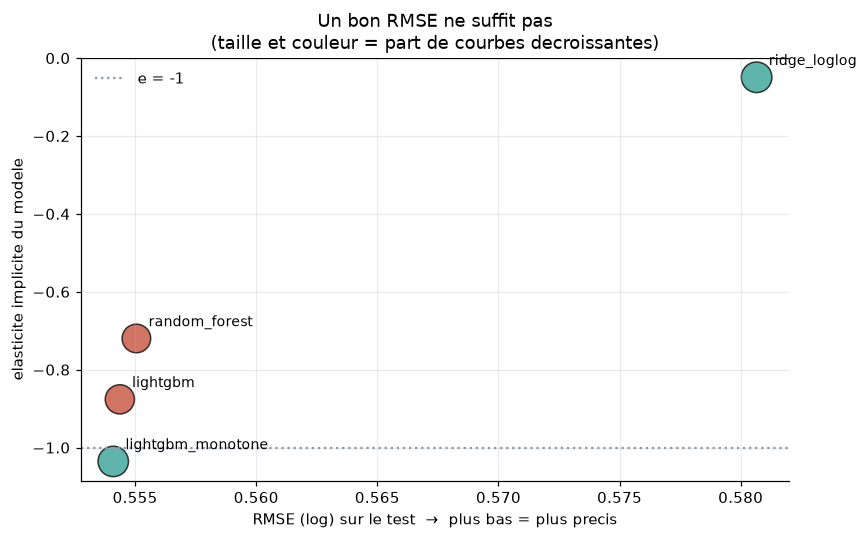

In [7]:
from optimization_pricing import plots

plots.plot_model_diagnostics(comparaison, save=True)
plt.show()

## 4. La règle de sélection, explicitée

```python
eligible = (share_decreasing >= 0.95) & (implied_elasticity <= -0.05)
best     = eligible.sort_values("test_rmse_log").iloc[0]
```

Un modèle plus précis mais économiquement incohérent est **écarté**. La
précision de prévision n'est pas l'objectif : la qualité de la décision
tarifaire l'est.

In [8]:
print(f"Modele retenu : {meilleur.name}")
print(f"Facteur de smearing : {meilleur.smearing:.4f}  "
      f"(la demande serait sous-estimee de {(1 - 1 / meilleur.smearing):.1%} sans correction)")

Modele retenu : lightgbm_monotone
Facteur de smearing : 1.1174  (la demande serait sous-estimee de 10.5% sans correction)


## 5. À quoi ressemble une courbe de demande prédite ?

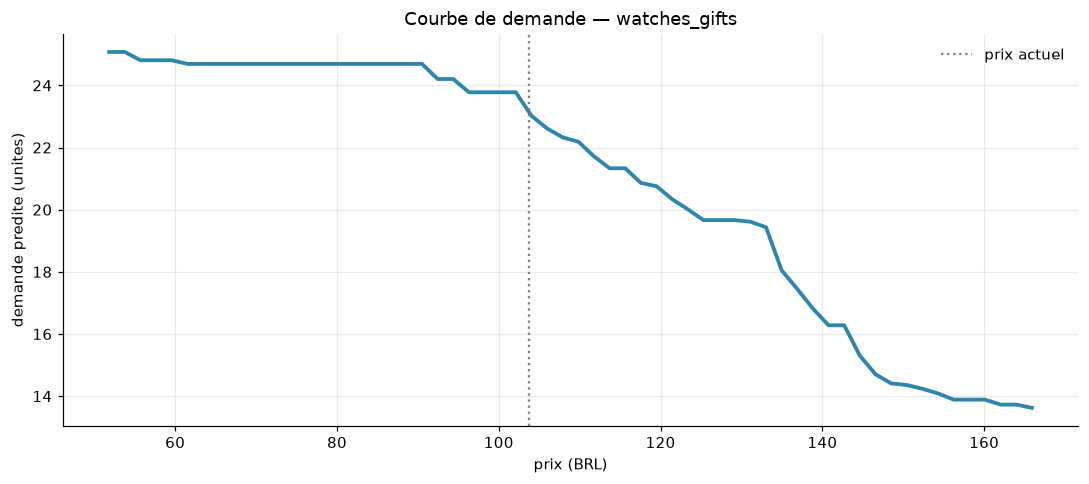

Courbe strictement decroissante : True


In [9]:
from optimization_pricing.features import apply_price_scenario

produit = test.nlargest(1, "quantity").reset_index(drop=True)
grille = np.linspace(produit["price"].iloc[0] * 0.5, produit["price"].iloc[0] * 1.6, 60)

scenarios = pd.concat([produit] * len(grille), ignore_index=True)
scenarios = apply_price_scenario(scenarios, grille)
demande = meilleur.predict_demand(scenarios)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(grille, demande, color="#2E86AB", lw=2.5)
ax.axvline(produit["price"].iloc[0], color="grey", ls=":", label="prix actuel")
ax.set_xlabel("prix (BRL)")
ax.set_ylabel("demande predite (unites)")
ax.set_title(f"Courbe de demande — {produit['product_category_name_english'].iloc[0]}")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print("Courbe strictement decroissante :", bool(np.all(np.diff(demande) <= 1e-9)))

La courbe est en escalier : c'est la signature d'un modèle d'arbres. Cela a une
conséquence pratique — mesurer l'élasticité locale par une différence finie trop
serrée (±1 %) tomberait souvent entre deux marches et renverrait zéro. D'où la
fenêtre de ±10 % utilisée dans `_local_elasticity`.

## 6. Ce que le modèle a appris

L'importance des variables dit *sur quoi* le modèle s'appuie. Si les variables
de prix étaient absentes du haut du classement, le modèle serait inutilisable
pour du pricing quel que soit son RMSE.

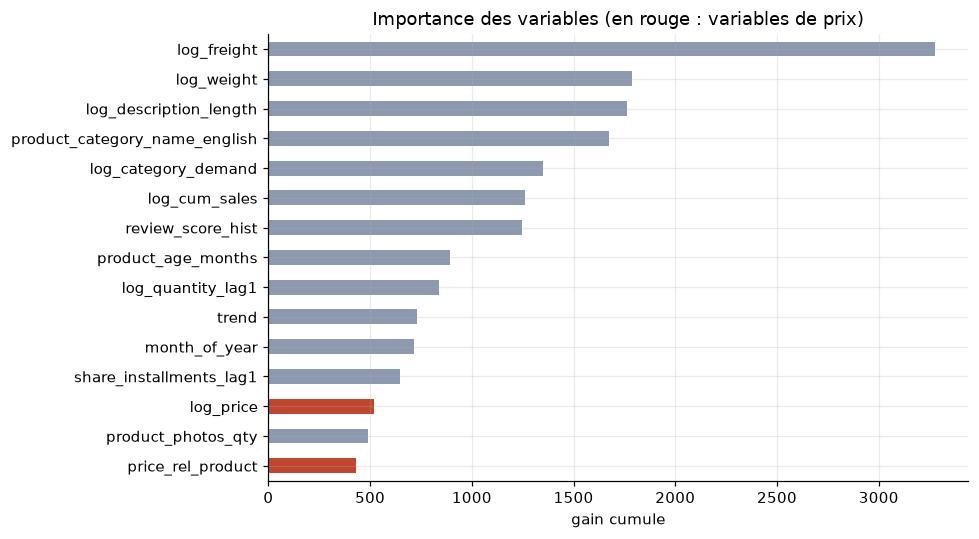

In [10]:
from optimization_pricing.config import FEATURES

importances = pd.Series(
    meilleur.estimator.feature_importances_, index=FEATURES
).sort_values(ascending=False)

couleurs = ["#C1462F" if f in PRICE_FEATURES else "#8D99AE" for f in importances.head(15).index]
importances.head(15).iloc[::-1].plot(kind="barh", color=couleurs[::-1], figsize=(9, 5))
plt.title("Importance des variables (en rouge : variables de prix)")
plt.xlabel("gain cumule")
plt.tight_layout()
plt.show()

## 7. Qualité des prédictions sur le jeu de test

In [11]:
from optimization_pricing.modeling.train import accuracy_metrics, price_response_metrics

metriques = {**accuracy_metrics(meilleur, test, "test_"), **price_response_metrics(meilleur, test)}
pd.Series(metriques).round(4).to_frame("valeur")

,valeur
test_rmse_log,0.554
test_mae_log,0.434
test_r2_log,0.403
test_rmse_units,2.912
test_mae_units,1.258
test_bias_units,-0.115
implied_elasticity,-1.036
implied_elasticity_median,-0.893
share_decreasing,0.992
share_flat,0.009


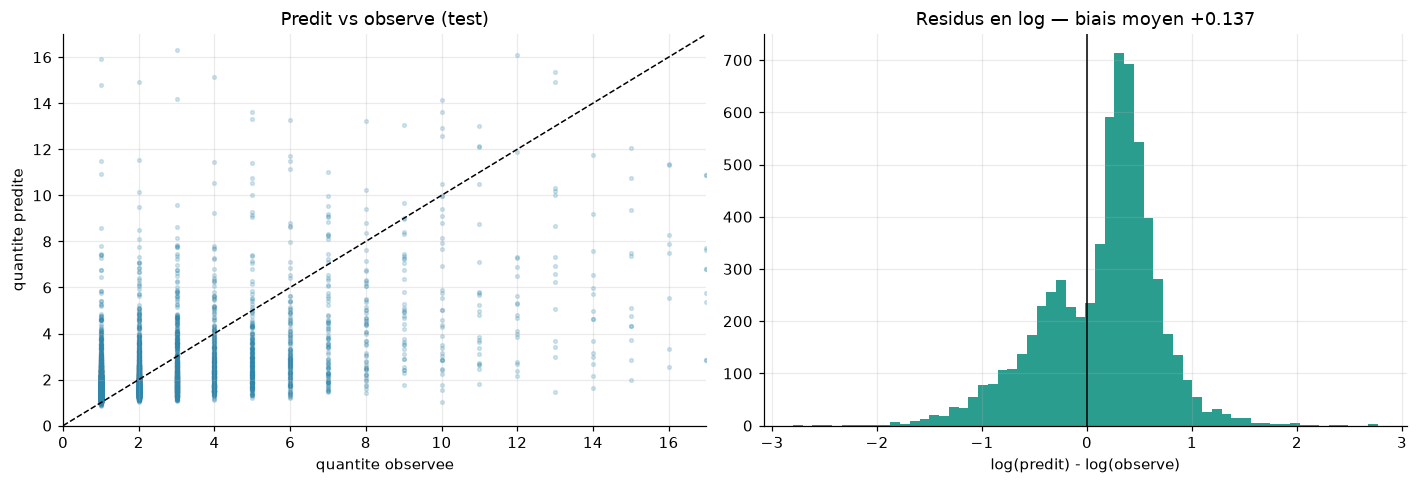

In [12]:
predictions = meilleur.predict_demand(test)
observees = test["quantity"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(observees, predictions, s=6, alpha=0.2, color="#2E86AB")
lim = [0, np.percentile(observees, 99)]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("quantite observee"); axes[0].set_ylabel("quantite predite")
axes[0].set_title("Predit vs observe (test)")

residus = np.log(np.clip(predictions, 1e-9, None)) - test["log_quantity"].to_numpy()
axes[1].hist(residus, bins=60, color="#2A9D8F")
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title(f"Residus en log — biais moyen {residus.mean():+.3f}")
axes[1].set_xlabel("log(predit) - log(observe)")
plt.tight_layout()
plt.show()

## Ce que ce notebook établit

* Split **temporel** obligatoire : les features contiennent des retards.
* **Smearing de Duan** appliqué : sans lui, la demande est sous-estimée et donc
  tous les profits simulés le sont aussi.
* **Contrainte de monotonie** imposée sur les trois variables de prix : c'est ce
  qui rend le problème d'optimisation bien posé.
* La sélection du modèle passe par un **filtre économique avant** le RMSE.
  `ridge_loglog` illustre pourquoi : meilleur uplift affiché, courbe plate,
  recommandations inutilisables.
* Modèle retenu : `lightgbm_monotone`, élasticité implicite cohérente avec
  l'estimation économétrique indépendante du notebook 04.

**Suite :** notebook 06, la transformation de cette courbe en décision de prix.